In [11]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam # optimizer
from tensorflow.keras.callbacks import Callback, EarlyStopping
from PIL import Image

# Fix every source of randomness so results can be reproduced
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
DATA_DIR = "split"            
SPLITS = {"train": "train", "val": "validation", "test": "test"}
IMG_EXT = (".pgm")

# ---- Settings ----
IMG_H, IMG_W = 60, 64              # height, width of every image
CLASSES = ["left", "right", "straight", "up"]
NUM_CLASSES = len(CLASSES)

def load_split(folder):
    #Load every image in a folder.

    X, y = [], []
    for root, _, files in os.walk(folder):
        for f in sorted(files):
            if not f.lower().endswith(IMG_EXT):
                continue                                      # skips .bad and other files
            img = np.asarray(Image.open(os.path.join(root, f)).convert("L"), dtype=np.float32)
            if img.shape != (IMG_H, IMG_W):                   # numpy shape is (height, width)
                raise ValueError(f"{f} has shape {img.shape}, expected {(IMG_H, IMG_W)}")
            X.append(img / 255.0)                             # scale pixels to [0, 1]
            y.append(CLASSES.index(os.path.splitext(f)[0].split("_")[1]))
    return np.stack(X)[..., None], np.array(y)               

X_train, y_train = load_split(os.path.join(DATA_DIR, SPLITS["train"]))
X_val,   y_val   = load_split(os.path.join(DATA_DIR, SPLITS["val"]))
X_test,  y_test  = load_split(os.path.join(DATA_DIR, SPLITS["test"]))

print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

Train: (436, 60, 64, 1)  Val: (93, 60, 64, 1)  Test: (95, 60, 64, 1)


In [13]:
# EpochTimer callback to record how long each epoch takes
class EpochTimer(Callback):
    # Records how long each epoch takes.
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.start)

In [14]:
# Load the pre-trained EfficinetNetB0 model
base_effnet = tf.keras.applications.EfficientNetB0(
    input_shape=(60, 64, 3), include_top=False, weights="imagenet")
base_effnet.trainable = False   #The pretrained weights will not change during training.

# Build the complete model
model_EffNetB0 = models.Sequential([
    layers.Input(shape=(60, 64, 3)),
    layers.Rescaling(255.0),          # 0–1 → 0–255; EfficientNet normalises internally
    base_effnet,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax"),
], name="EfficientNetB0")

model_EffNetB0.summary()

Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 60, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 2, 2, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [15]:
model_EffNetB0.compile(optimizer=Adam(1e-3),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
timer_head = EpochTimer()
history_EffNetB0_head = model_EffNetB0.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=32, callbacks=[timer_head], verbose=1)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 374ms/step - accuracy: 0.4794 - loss: 1.2147 - val_accuracy: 0.7097 - val_loss: 0.8391
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.7225 - loss: 0.7602 - val_accuracy: 0.7849 - val_loss: 0.5823
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - accuracy: 0.8028 - loss: 0.5910 - val_accuracy: 0.8602 - val_loss: 0.4490
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.8601 - loss: 0.4524 - val_accuracy: 0.9570 - val_loss: 0.3342
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.8991 - loss: 0.3474 - val_accuracy: 0.9462 - val_loss: 0.2759
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.9083 - loss: 0.3129 - val_accuracy: 0.9677 - val_loss: 0.2300
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.9243 - loss: 0.2621 - val_accuracy: 0.9677 - val_loss: 0.1919
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.9243 - loss: 0.2423 - val_accuracy: 0.967

In [16]:
# Fine tuning the model

base_effnet.trainable = True
fine_tune_from = len(base_effnet.layers) - 30   # Fine-tune the last 30 layers of the model
for layer in base_effnet.layers[:fine_tune_from]:   # Freeze all layers except the last 30
    layer.trainable = False
for layer in base_effnet.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(int(tf.size(w)) for w in model_EffNetB0.trainable_weights)
print(f"Trainable params during fine-tuning: {n_trainable:,}")

model_EffNetB0.compile(optimizer=Adam(1e-5),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
timer_ft = EpochTimer()
history_EffNetB0_ft = model_EffNetB0.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=32, callbacks=[timer_ft], verbose=1)

Trainable params during fine-tuning: 1,647,844
Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 25s 412ms/step - accuracy: 0.9862 - loss: 0.0772 - val_accuracy: 1.0000 - val_loss: 0.0377
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.9839 - loss: 0.0781 - val_accuracy: 1.0000 - val_loss: 0.0441
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.9977 - loss: 0.0432 - val_accuracy: 1.0000 - val_loss: 0.0371
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.9862 - loss: 0.0647 - val_accuracy: 1.0000 - val_loss: 0.0323
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.9908 - loss: 0.0573 - val_accuracy: 1.0000 - val_loss: 0.0317
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.9977 - loss: 0.0395 - val_accuracy: 1.0000 - val_loss: 0.0333
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.9885 - loss: 0.0554 - val_accuracy: 1.0000 - val_loss: 0.0326
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 242ms/step - ac

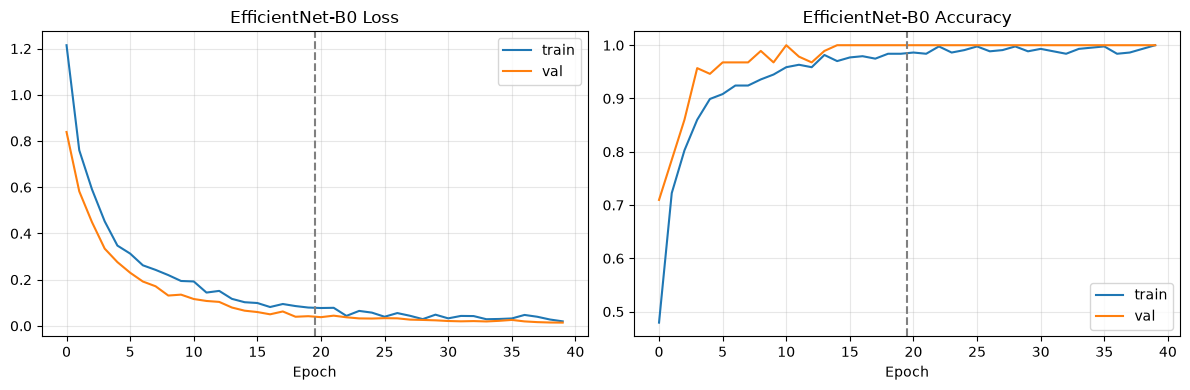

In [17]:

h = {k: history_EffNetB0_head.history[k] + history_EffNetB0_ft.history[k]
     for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(h["loss"], label="train"); ax1.plot(h["val_loss"], label="val")
ax2.plot(h["accuracy"], label="train"); ax2.plot(h["val_accuracy"], label="val")
for ax, t in [(ax1, "Loss"), (ax2, "Accuracy")]:
    ax.axvline(19.5, ls="--", c="gray")           # start of fine-tuning
    ax.set_title(f"EfficientNet-B0 {t}"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [18]:
test_loss_EffNetB0, test_accuracy_EffNetB0 = model_EffNetB0.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss_EffNetB0:.4f}")
print(f"Test Accuracy: {test_accuracy_EffNetB0:.4f}")
print(f"Test Accuracy: {test_accuracy_EffNetB0*100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 1.0000 - loss: 0.0253
Test Loss: 0.0253
Test Accuracy: 1.0000
Test Accuracy: 100.00%


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


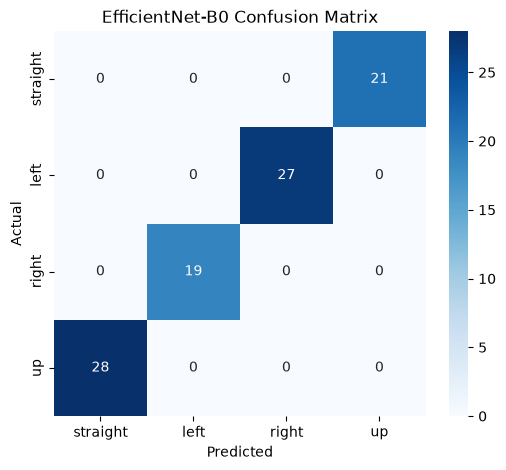

              precision    recall  f1-score   support

    straight     0.0000    0.0000    0.0000      21.0
        left     0.0000    0.0000    0.0000      27.0
       right     0.0000    0.0000    0.0000      19.0
          up     0.0000    0.0000    0.0000      28.0

    accuracy                         0.0000      95.0
   macro avg     0.0000    0.0000    0.0000      95.0
weighted avg     0.0000    0.0000    0.0000      95.0



In [22]:
y_pred_prob_EffNetB0 = model_EffNetB0.predict(X_test)
y_pred_EffNetB0 = np.argmax(y_pred_prob_EffNetB0, axis=1)

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_EffNetB0)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNet-B0 Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred_EffNetB0,
    target_names=CLASSES,
    digits=4
))

In [20]:
model_EffNetB0.save_weights("EfficientNetB0_CMU_Face.weights.h5")
print(f"Total params:        {model_EffNetB0.count_params():,}")
print(f"Size on disk:        {os.path.getsize('EfficientNetB0_CMU_Face.weights.h5')/1024:.1f} KB")
print(f"s/epoch (head):      {np.mean(timer_head.times[1:]):.3f}")
print(f"s/epoch (fine-tune): {np.mean(timer_ft.times[1:]):.3f}")

Total params:        4,214,055
Size on disk:        29957.5 KB
s/epoch (head):      1.432
s/epoch (fine-tune): 2.365
